In [1]:
import numpy as np
import pandas as pd
import pickle
import warnings
import time as time_mod
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    classification_report, f1_score, roc_auc_score,
    brier_score_loss, precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_sample_weight
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Core ──────────────────────────────────────────────────────────────────────
N_TOTAL    = 9330
N_GMM      = 4
SEQ_LEN    = 30
TRAIN_END  = 6531
GAP        = SEQ_LEN
VAL_START  = TRAIN_END + GAP
VAL_END    = 7930
VAL_MID    = (VAL_START + VAL_END) // 2
TEST_START = VAL_END + GAP
TEST_END   = N_TOTAL

REGIME_NAMES       = {0:'BULL_TREND', 1:'BEAR_TREND', 2:'RANGE_CHOP', 3:'ANOMALY'}
EXCL_REGIMES_TRAIN = {2, 3}

ATR_ROLL_WIN = 50
ATR_ROLL_PCT = 0.30

# ── ICM broker costs ──────────────────────────────────────────────────────────
ICM_COMMISSION = 0.70
ICM_SLIPPAGE   = 0.50
ICM_COST_FIXED = ICM_COMMISSION + ICM_SLIPPAGE   # 1.20 pips RT

# ── Dynamic cost buffer ────────────────────────────────────────────────────────
COST_BUFFER_HIGH = 0.50
COST_BUFFER_MID  = 0.30
COST_BUFFER_LOW  = 0.20
ATR_PCT_HIGH = None
ATR_PCT_LOW  = None
COST_ATR_RATIO    = 0.20
ATR_QUALITY_FLOOR = 12.0

# ── v18.7: Updated PROB_GATE (swing calibration) ──────────────────────────────
# Analysis: PROB_GATE=0.53 with edge filter is fine for NORMAL/WEAK folds.
# Edge filter blocks 0.53 signals (59pip < 60pip NORMAL margin).
# However: raise REGIME_PROB_GATES to reflect swing context (200pip TP).
PROB_GATE = 0.53   # main model unchanged (edge filter handles it)

# v18.7: Swing-calibrated per-regime gates (BULL 0.54→0.55, BEAR 0.53→0.54)
REGIME_PROB_GATES = {
    0: 0.55,   # BULL_TREND — v18.7: raised 0.54→0.55 (swing calibration)
    1: 0.54,   # BEAR_TREND — v18.7: raised 0.53→0.54
    2: 0.58,   # RANGE_CHOP — rarely traded (raised from 0.57)
    3: 0.62,   # ANOMALY    — very rarely traded
}

REGIME_MIN_TRADES = 10

UNCERT_MARGIN = {
    0: 0.04,   # BULL_TREND (unchanged)
    1: 0.04,   # BEAR_TREND (unchanged)
    2: 0.06,   # RANGE_CHOP (unchanged)
    3: 0.08,   # ANOMALY (unchanged)
}

# ── v18.7: Fold-quality adaptive TP/SL multipliers ────────────────────────────
# Fix 2 (refined): Not per-regime (already handled by DYNAMIC_HOLD_REGIMES),
# but per FOLD QUALITY within BULL/BEAR.
# WEAK fold (2024 ranging) → lower TP → more realistic capture probability
TP_SL_BY_QUALITY = {
    'STRONG': (8.0, 4.0),   # TP=200pip SL=100pip (200% of ATR25)
    'NORMAL': (7.0, 3.5),   # TP=175pip SL=87pip
    'WEAK':   (6.0, 3.0),   # TP=150pip SL=75pip (more realistic for ranging)
}
# Defaults for main model (assume STRONG quality for test set)
TP_MULT_DEFAULT = 8.0
SL_MULT_DEFAULT = 4.0
RR_DEFAULT      = TP_MULT_DEFAULT / SL_MULT_DEFAULT  # = 2.0

# ── v18.7: Runner logic ───────────────────────────────────────────────────────
# Split position: TP1_FRACTION at TP1, RUNNER_FRACTION continues
# Sim model: Runner wins add RUNNER_EXTRA_MULT×ATR; SL moved to BE after TP1
TP1_FRACTION    = 0.70   # close 70% at TP1
RUNNER_FRACTION = 0.30   # trail 30%
RUNNER_EXTRA_MULT = 4.0  # runner captures ATR×4 extra on extended moves
# Math: Win = 0.70×TP1 + 0.30×(TP1 + RUNNER_EXTRA_MULT×ATR)
#       Loss = -SL (TP1 not reached, original SL hit)

# ── v18.7: Time exit simulation ───────────────────────────────────────────────
# Critical: without time exit, PPT overstated vs live trading
# 4H × 20 bars = 80 hours = ~3.3 trading days (reasonable swing horizon)
MAX_HOLD_BARS     = 20     # bars before forced time exit
# Time exit PnL: -cost only (flat, just costs — conservative and honest)
# This models: trade never resolved → exit at entry price → only costs

# ── v18.7: Dynamic edge scaling ───────────────────────────────────────────────
# User's advanced suggestion: higher ATR → require higher edge margin
# Prevents entering in explosive volatile conditions with only marginal edge
EDGE_BASE_STRONG = 40.0
EDGE_BASE_NORMAL = 60.0
EDGE_BASE_WEAK   = 80.0
EDGE_ATR_SCALE   = 0.30   # additional pip required per pip of ATR

# ── Fold quality ──────────────────────────────────────────────────────────────
FOLD_QUALITY_STRONG_PPT = 10.0
FOLD_QUALITY_NORMAL_PPT =  7.0
FOLD_GATE_ADJ = {'STRONG': 0.00, 'NORMAL': 0.02, 'WEAK': 0.04}

def classify_fold_quality(val_ppt):
    if val_ppt >= FOLD_QUALITY_STRONG_PPT: return 'STRONG'
    if val_ppt >= FOLD_QUALITY_NORMAL_PPT: return 'NORMAL'
    return 'WEAK'

def get_fold_regime_gates(fold_quality):
    adj = FOLD_GATE_ADJ[fold_quality]
    return {rg: min(gate + adj, 0.68) for rg, gate in REGIME_PROB_GATES.items()}

def get_fold_tp_sl(fold_quality):
    return TP_SL_BY_QUALITY[fold_quality]

# ── WF model (unchanged from v18.5) ───────────────────────────────────────────
WF_ITERATIONS     = 115
WF_L2             = 12
WF_REGIME_WEIGHTS = {0:0.8, 1:0.8, 2:1.2, 3:1.2}
WF_THRESH_SWEEP   = [0.54, 0.55, 0.56, 0.57]
WF_THRESH_LOCKED  = 0.55

WF_GAP_TARGET    = 0.06
WF_GAP_STD_WARN  = 0.025
WF_MINFOLDS_POS  = 4

# ── TOP_K ─────────────────────────────────────────────────────────────────────
TOP_K_BASE         = 55
TOP_K_MAX          = 62
TOP_K_ANCHOR_FEATS = ['momentum_velocity','bos_strength','trend_strength_ema',
                       'choch_signal','bos_signal']
TOP_K_ANCHOR_MIN   = 3

print('NB-E-ML v18.7 — Institutional Swing Execution (Final)')
print(f'  PROB_GATE={PROB_GATE} | REGIME_GATES={REGIME_PROB_GATES}')
print(f'  TP/SL by quality: {TP_SL_BY_QUALITY}')
print(f'  Runner: TP1_FRAC={TP1_FRACTION}  RUNNER_FRAC={RUNNER_FRACTION}  EXTRA={RUNNER_EXTRA_MULT}×ATR')
print(f'  Time exit: MAX_HOLD_BARS={MAX_HOLD_BARS} (4H×{MAX_HOLD_BARS}={MAX_HOLD_BARS*4}h)')
print(f'  Dynamic edge: base + {EDGE_ATR_SCALE}×ATR')
print(f'  WF: trees={WF_ITERATIONS}  l2={WF_L2}  regime_weights={WF_REGIME_WEIGHTS}')


NB-E-ML v18.7 — Institutional Swing Execution (Final)
  PROB_GATE=0.53 | REGIME_GATES={0: 0.55, 1: 0.54, 2: 0.58, 3: 0.62}
  TP/SL by quality: {'STRONG': (8.0, 4.0), 'NORMAL': (7.0, 3.5), 'WEAK': (6.0, 3.0)}
  Runner: TP1_FRAC=0.7  RUNNER_FRAC=0.3  EXTRA=4.0×ATR
  Time exit: MAX_HOLD_BARS=20 (4H×20=80h)
  Dynamic edge: base + 0.3×ATR
  WF: trees=115  l2=12  regime_weights={0: 0.8, 1: 0.8, 2: 1.2, 3: 1.2}


In [2]:
with open('B_scaled_v6_clean.pkl','rb') as fh:
    B = pickle.load(fh)
X_base_all = B['X_scaled'].astype(np.float64)
feat_cols  = list(B['FEATURES_FINAL'])
times      = pd.to_datetime(B['times'])
assert X_base_all.shape == (N_TOTAL, 103) and np.isnan(X_base_all).sum() == 0
print(f'B_scaled: {X_base_all.shape}')

with open('D_clusters_v9.pkl','rb') as fh:
    D9 = pickle.load(fh)
gmm_labels = np.array(D9['gmm_labels'],       dtype=np.int64)
gmm_probs  = np.array(D9['gmm_probs'],        dtype=np.float64)
hmm_probs  = np.array(D9['hmm_state_probs'],  dtype=np.float64)
df_cl      = D9['df_clusters']
assert (gmm_probs.argmax(1) == gmm_labels).mean() > 0.99
print(f'D_clusters: N_GMM={D9["N_GMM"]}')

df_raw = pd.read_csv('A_features_clean_v2.csv')
assert len(df_raw) == N_TOTAL

atr_col = 'atr_14_pips' if 'atr_14_pips' in df_raw.columns else 'atr_14'
atr_raw = df_raw[atr_col].fillna(0).values.astype(np.float64)
if atr_col == 'atr_14': atr_raw = atr_raw * 10000
ATR_MED = float(np.median(atr_raw[atr_raw > 0]))
atr_roll = (pd.Series(atr_raw).rolling(ATR_ROLL_WIN, min_periods=20)
            .quantile(ATR_ROLL_PCT).bfill()
            .fillna(ATR_MED * ATR_ROLL_PCT).values.astype(np.float64))

spr_col    = 'spread_d1' if 'spread_d1' in df_raw.columns else 'spread_pips'
spread_raw = (df_raw[spr_col].fillna(1.5).values.astype(np.float64)
              if spr_col in df_raw.columns else np.full(N_TOTAL, 1.5))
news_all   = (df_raw['is_news_event'].fillna(0).values.astype(int)
              if 'is_news_event' in df_raw.columns else np.zeros(N_TOTAL, int))

print(f'ATR median: {ATR_MED:.1f} pip')
print(f'  STRONG fold: TP≈{ATR_MED*8:.0f}pip  SL≈{ATR_MED*4:.0f}pip  RR=2:1')
print(f'  NORMAL fold: TP≈{ATR_MED*7:.0f}pip  SL≈{ATR_MED*3.5:.0f}pip  RR=2:1')
print(f'  WEAK fold:   TP≈{ATR_MED*6:.0f}pip  SL≈{ATR_MED*3:.0f}pip  RR=2:1')

readd_names = []; X_readd = np.empty((N_TOTAL, 0))

atr_train    = atr_raw[:TRAIN_END][atr_raw[:TRAIN_END] > 0]
ATR_PCT_HIGH = float(np.percentile(atr_train, 70))
ATR_PCT_LOW  = float(np.percentile(atr_train, 30))
print(f'ATR pct: P30={ATR_PCT_LOW:.1f}  P70={ATR_PCT_HIGH:.1f}')

df_tgt = pd.read_csv('A_target_v5.csv')
y3     = df_tgt['ml_target'].values.astype(np.int64)
y_bin  = np.where(y3 == 2, 1, 0).astype(np.int64)
print(f'Target: SELL={(y3==0).sum()} NEU={(y3==1).sum()} BUY={(y3==2).sum()}')


B_scaled: (9330, 103)
D_clusters: N_GMM=4
ATR median: 27.9 pip
  STRONG fold: TP≈223pip  SL≈111pip  RR=2:1
  NORMAL fold: TP≈195pip  SL≈98pip  RR=2:1
  WEAK fold:   TP≈167pip  SL≈84pip  RR=2:1
ATR pct: P30=24.4  P70=33.8
Target: SELL=3470 NEU=2446 BUY=3414


In [3]:
gp_use = gmm_probs.copy(); hp_use = hmm_probs.copy()
gp_use[gmm_probs.max(1) < 0.70] = 1.0/N_GMM
hp_use[hmm_probs.max(1) < 0.70] = 1.0/N_GMM
X_udl = np.hstack([gp_use, hp_use,
                   gmm_probs.max(1,keepdims=True), hmm_probs.max(1,keepdims=True),
                   df_cl['size_mult'].values.reshape(-1,1)])
udl_names = ([f'gmm_p{i}' for i in range(N_GMM)] +
             [f'hmm_p{i}' for i in range(N_GMM)] +
             ['gmm_conf','hmm_conf','size_mult'])
X_all = np.hstack([X_base_all, X_udl, X_readd])
all_feat_names = feat_cols + udl_names + readd_names
assert np.isnan(X_all).sum()==0 and np.isinf(X_all).sum()==0
print(f'Feature matrix: {X_all.shape}')

FORCE_FEATURES = ['momentum_velocity','trend_strength_ema','bos_strength','momentum_regime_scaled']
force_idx = []
for f in FORCE_FEATURES:
    if f in all_feat_names:
        force_idx.append(all_feat_names.index(f)); print(f'  Force-include: {f}')
    else:
        print(f'  WARNING: {f} not found')
print(f'  Forced: {len(force_idx)} features')


Feature matrix: (9330, 114)
  Force-include: momentum_velocity
  Force-include: trend_strength_ema
  Force-include: bos_strength
  Force-include: momentum_regime_scaled
  Forced: 4 features


In [4]:
idx_tr_all = np.arange(0, TRAIN_END)
tr_ok = (y3[idx_tr_all]!=1) & ~np.isin(gmm_labels[idx_tr_all], list(EXCL_REGIMES_TRAIN))
sc_mi = StandardScaler().fit(X_all[idx_tr_all][tr_ok])
mi    = mutual_info_classif(sc_mi.transform(X_all[idx_tr_all][tr_ok]),
                             y_bin[idx_tr_all][tr_ok],
                             discrete_features=False, n_neighbors=5, random_state=42)
mi_rank = np.argsort(mi)[::-1]

top_k_working = TOP_K_BASE
for _ in range(TOP_K_MAX - TOP_K_BASE + 1):
    cand_feat = [all_feat_names[i] for i in mi_rank[:top_k_working]]
    n_anchors = sum(1 for a in TOP_K_ANCHOR_FEATS if a in cand_feat)
    if n_anchors >= TOP_K_ANCHOR_MIN or top_k_working >= TOP_K_MAX: break
    top_k_working += 1

TOP_K_FEAT = top_k_working
top_k_idx  = np.sort(np.array(mi_rank[:TOP_K_FEAT], dtype=int))
feat_sel   = [all_feat_names[i] for i in top_k_idx]
anchors_found = [a for a in TOP_K_ANCHOR_FEATS if a in feat_sel]
print(f'TOP_K: {TOP_K_BASE}→{TOP_K_FEAT} | anchors: {anchors_found}')
print(f'Top 10 MI: {[all_feat_names[i] for i in mi_rank[:10]]}')
X_ml = X_all[:, top_k_idx]

CAT_COL_NAMES = ['setup_type_encoded','session_enc','trend_enc',
                 'trend_strength_enc','vol_regime_enc','gap_type_enc']
cat_feat_idx = [i for i,f in enumerate(feat_sel) if f in CAT_COL_NAMES]
print(f'Cat features ({len(cat_feat_idx)}): {[feat_sel[i] for i in cat_feat_idx]}')

idx_tr = np.arange(0, TRAIN_END)
idx_vA = np.arange(VAL_START, VAL_MID)
idx_vB = np.arange(VAL_MID,   VAL_END)
idx_te = np.arange(TEST_START, TEST_END)

def make_ml_xy(idx_block, excl_regimes=None, shift=True):
    if excl_regimes is None: excl_regimes = EXCL_REGIMES_TRAIN
    Xr,ys,rgs,atrs,rolls,sprs,news = [],[],[],[],[],[],[]
    for i in idx_block:
        if y3[i]==1: continue
        if int(gmm_labels[i]) in excl_regimes: continue
        fi = (i-1) if shift else i
        if fi<0 or fi>=len(X_ml): continue
        Xr.append(X_ml[fi]); ys.append(y_bin[i])
        rgs.append(int(gmm_labels[i])); atrs.append(float(atr_raw[i]))
        rolls.append(float(atr_roll[i])); sprs.append(float(spread_raw[i]))
        news.append(int(news_all[i]))
    return (np.array(Xr,np.float64),np.array(ys,np.int64),np.array(rgs,np.int64),
            np.array(atrs,np.float32),np.array(rolls,np.float32),
            np.array(sprs,np.float32),np.array(news,np.int32))

Xtr,ytr,rgtr,atrtr,rolltr,sprtr,newstr = make_ml_xy(idx_tr)
XvA,yvA,rgvA,atrvA,rollvA,sprvA,newsvA = make_ml_xy(idx_vA)
XvB,yvB,rgvB,atrvB,rollvB,sprvB,newsvB = make_ml_xy(idx_vB)
Xte,yte,rgte,atrte,rollte,sprte,newste  = make_ml_xy(idx_te)

for nm,X,y in [('Train',Xtr,ytr),('Val_A',XvA,yvA),('Val_B',XvB,yvB),('Test',Xte,yte)]:
    s=(y==0).sum(); b=(y==1).sum()
    print(f'  {nm:<8}: {X.shape}  SELL={s}({s/len(y)*100:.0f}%) BUY={b}({b/len(y)*100:.0f}%)')

sw_train  = compute_sample_weight('balanced',ytr)
scaler_lr = StandardScaler()
Xtr_sc=scaler_lr.fit_transform(Xtr); XvA_sc=scaler_lr.transform(XvA)
XvB_sc=scaler_lr.transform(XvB);     Xte_sc=scaler_lr.transform(Xte)


TOP_K: 55→62 | anchors: ['momentum_velocity', 'trend_strength_ema']
Top 10 MI: ['spread_w1', 'spread_vs_atr', 'spread_d1', 'range_break', 'supply_ob', 'is_high_vol', 'demand_ob_strength', 'atr_14_pips', 'price_roc_3', 'macd_hist_norm']
Cat features (4): ['setup_type_encoded', 'session_enc', 'trend_strength_enc', 'vol_regime_enc']
  Train   : (3275, 62)  SELL=1683(51%) BUY=1592(49%)
  Val_A   : (336, 62)  SELL=151(45%) BUY=185(55%)
  Val_B   : (357, 62)  SELL=213(60%) BUY=144(40%)
  Test    : (666, 62)  SELL=288(43%) BUY=378(57%)


In [5]:
def calibrate_and_score(trained_clf, XvA, yvA, Xte, yte, name):
    cal  = CalibratedClassifierCV(trained_clf, method='sigmoid', cv='prefit')
    cal.fit(XvA,yvA)
    vpr=cal.predict_proba(XvA); tpr=cal.predict_proba(Xte)
    vauc=roc_auc_score(yvA,vpr[:,1]); tauc=roc_auc_score(yte,tpr[:,1])
    bs=brier_score_loss(yte,tpr[:,1])
    tf1=f1_score(yte,cal.predict(Xte),average='macro',zero_division=0)
    gap=vauc-tauc; icon='✅' if gap<0.04 else '⚠' if gap<0.06 else '❌'
    print(f'{icon} {name:<40} val={vauc:.4f}  test={tauc:.4f}  '
          f'gap={gap:+.4f}  f1={tf1:.4f}  brier={bs:.4f}')
    return cal,vpr,tpr,tf1,vauc,tauc,bs
t0 = time_mod.time()

cat_base = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.03,
    depth=4,
    l2_leaf_reg=12,
    bagging_temperature=4,
    random_strength=2,
    min_data_in_leaf=20,
    early_stopping_rounds=50,
    use_best_model=True,
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0
)

cat_fit_kwargs = {'eval_set': Pool(XvA, yvA)}

# Do NOT pass cat_features here because Xtr/XvA are float numpy arrays
cat_base.fit(Xtr, ytr, **cat_fit_kwargs)

cat_clf, cat_vpr, cat_tpr, cat_tf1, cat_vauc, cat_tauc, cat_bs = \
    calibrate_and_score(cat_base, XvA, yvA, Xte, yte, 'CatBoost+Cal v18.7 [PRIMARY]')

print(f'  trees={cat_base.best_iteration_}  time={time_mod.time()-t0:.1f}s')

lr_conf=LogisticRegression(C=0.1,class_weight='balanced',max_iter=1000,random_state=42,n_jobs=-1)
lr_conf.fit(Xtr_sc,ytr)
lr_te_prob=lr_conf.predict_proba(Xte_sc)[:,1]; lr_vB_prob=lr_conf.predict_proba(XvB_sc)[:,1]
lr_tauc=roc_auc_score(yte,lr_te_prob); lr_vauc=roc_auc_score(yvB,lr_vB_prob)
print(f'  LR: val_B={lr_vauc:.4f}  test={lr_tauc:.4f}')

t0=time_mod.time()
lgbm_base=lgb.LGBMClassifier(n_estimators=1000,learning_rate=0.03,num_leaves=31,max_depth=6,
    min_child_samples=40,subsample=0.80,colsample_bytree=0.70,reg_alpha=0.10,reg_lambda=0.20,
    boosting_type='dart',drop_rate=0.10,random_state=42,verbosity=-1,n_jobs=-1)
lgbm_base.fit(Xtr,ytr,sample_weight=sw_train,eval_set=[(XvA,yvA)],callbacks=[lgb.log_evaluation(-1)])
lgbm_clf,lgbm_vpr,lgbm_tpr,lgbm_tf1,lgbm_vauc,lgbm_tauc,lgbm_bs = \
    calibrate_and_score(lgbm_base,XvA,yvA,Xte,yte,'LGBM-DART+Cal [diag]')

t0=time_mod.time()
xgb_base=xgb.XGBClassifier(n_estimators=1000,learning_rate=0.03,max_depth=5,
    min_child_weight=5,subsample=0.80,colsample_bytree=0.70,reg_alpha=0.10,reg_lambda=1.0,
    eval_metric='logloss',early_stopping_rounds=50,random_state=42,verbosity=0,n_jobs=-1)
xgb_base.fit(Xtr,ytr,sample_weight=sw_train,eval_set=[(XvA,yvA)],verbose=False)
xgb_clf,xgb_vpr,xgb_tpr,xgb_tf1,xgb_vauc,xgb_tauc,xgb_bs = \
    calibrate_and_score(xgb_base,XvA,yvA,Xte,yte,'XGB+Cal [diag]')


✅ CatBoost+Cal v18.7 [PRIMARY]             val=0.8912  test=0.8691  gap=+0.0222  f1=0.7810  brier=0.1466
  trees=202  time=4.0s
  LR: val_B=0.9269  test=0.8811
✅ LGBM-DART+Cal [diag]                     val=0.8778  test=0.8530  gap=+0.0248  f1=0.7601  brier=0.1612
✅ XGB+Cal [diag]                           val=0.8985  test=0.8704  gap=+0.0281  f1=0.7671  brier=0.1496


In [6]:
# ── Cost / quality gates (unchanged from v18.4+) ─────────────────────────────
def get_dynamic_buffer(atr_v):
    if ATR_PCT_HIGH is None or ATR_PCT_LOW is None: return COST_BUFFER_MID
    if atr_v >= ATR_PCT_HIGH: return COST_BUFFER_HIGH
    if atr_v <= ATR_PCT_LOW:  return COST_BUFFER_LOW
    return COST_BUFFER_MID

def get_uncert_margin(rg):
    return UNCERT_MARGIN.get(int(rg), 0.04)

def passes_cost_gate(atr_v, spr, cost_fixed=ICM_COST_FIXED):
    if atr_v < ATR_QUALITY_FLOOR: return False
    cost_eff = spr + cost_fixed + get_dynamic_buffer(atr_v)
    return atr_v > 0 and (cost_eff / atr_v) <= COST_ATR_RATIO

# ── v18.7: Dynamic edge scaling ───────────────────────────────────────────────
def get_edge_margin(base_margin, atr_v):
    """v18.7: base_margin + EDGE_ATR_SCALE * ATR.
    High-vol bars require more expected edge before trading.
    """
    return base_margin + EDGE_ATR_SCALE * atr_v

# ── v18.7: Swing PnL with runner logic ───────────────────────────────────────
def compute_swing_pnl(sig, true_label, atr_v, spr,
                      tp_mult=TP_MULT_DEFAULT, sl_mult=SL_MULT_DEFAULT,
                      cost_fixed=ICM_COST_FIXED,
                      use_runner=True):
    """v18.7: Swing trade PnL with optional runner logic.
    
    Runner model (use_runner=True):
      Win:  0.70*TP + 0.30*(TP + RUNNER_EXTRA_MULT*ATR)
      Loss: -SL  (TP1 not hit, original SL triggered)
    
    Simple model (use_runner=False):
      Win:  +TP
      Loss: -SL
    
    NOTE: PnL uses real ICM cost (no buffer). Conservative and accurate.
    """
    tp        = atr_v * tp_mult
    sl        = atr_v * sl_mult
    is_win    = (sig == 1 and true_label == 1) or (sig == 0 and true_label == 0)
    cost      = spr + cost_fixed

    if use_runner:
        if is_win:
            runner_extra = atr_v * RUNNER_EXTRA_MULT
            raw_pnl = TP1_FRACTION * tp + RUNNER_FRACTION * (tp + runner_extra)
        else:
            raw_pnl = -sl
    else:
        raw_pnl = tp if is_win else -sl

    return raw_pnl - cost

# ── v18.7: Time exit PnL ──────────────────────────────────────────────────────
def compute_time_exit_pnl(spr, cost_fixed=ICM_COST_FIXED):
    """v18.7: Flat time exit — only costs, no directional gain.
    Conservative and honest: models 'trade held too long, closed at entry'.
    Used when MAX_HOLD_BARS exceeded in simulation.
    """
    return -(spr + cost_fixed)   # just the round-trip cost

# ── v18.7: Expected-edge filter with dynamic scaling ──────────────────────────
def compute_expected_edge(prob, atr_v, spr,
                          tp_mult=TP_MULT_DEFAULT, sl_mult=SL_MULT_DEFAULT,
                          cost_fixed=ICM_COST_FIXED, use_runner=True):
    """EV = prob*expected_win + (1-prob)*expected_loss - cost.
    Uses runner model for consistent edge estimation.
    """
    tp = atr_v * tp_mult; sl = atr_v * sl_mult
    p_dir = max(prob, 1 - prob)  # probability in signal direction
    cost  = spr + cost_fixed

    if use_runner:
        runner_extra = atr_v * RUNNER_EXTRA_MULT
        win_val  = TP1_FRACTION * tp + RUNNER_FRACTION * (tp + runner_extra)
        loss_val = sl
    else:
        win_val  = tp; loss_val = sl

    return p_dir * win_val - (1 - p_dir) * loss_val - cost

def passes_edge_filter(prob, atr_v, spr, base_margin,
                       tp_mult=TP_MULT_DEFAULT, sl_mult=SL_MULT_DEFAULT,
                       cost_fixed=ICM_COST_FIXED):
    """v18.7: passes if expected_edge > dynamic_margin (base + 0.3*ATR)."""
    edge   = compute_expected_edge(prob, atr_v, spr, tp_mult, sl_mult, cost_fixed)
    margin = get_edge_margin(base_margin, atr_v)
    return edge > margin

def get_regime_sample_weight(regimes_arr):
    weights = np.ones(len(regimes_arr), dtype=np.float32)
    for i,rg in enumerate(regimes_arr):
        weights[i] = WF_REGIME_WEIGHTS.get(int(rg), 1.0)
    return weights

# ── Verification ──────────────────────────────────────────────────────────────
print('v18.7 utility functions:')
test_atr=25.0; test_spr=1.5; test_prob=0.55
tp=test_atr*TP_MULT_DEFAULT; sl=test_atr*SL_MULT_DEFAULT
print(f'  TP={tp:.0f}pip  SL={sl:.0f}pip  RR={TP_MULT_DEFAULT/SL_MULT_DEFAULT:.1f}:1')
win  = compute_swing_pnl(1,1,test_atr,test_spr,use_runner=True)
loss = compute_swing_pnl(1,0,test_atr,test_spr,use_runner=True)
print(f'  Runner win={win:.0f}pip  Runner loss={loss:.0f}pip')
ev83 = 0.83*win + 0.17*loss
ev70 = 0.70*win + 0.30*loss
print(f'  EV@83%={ev83:.0f}pip  EV@70%={ev70:.0f}pip')
edge = compute_expected_edge(test_prob,test_atr,test_spr)
dyn_margin = get_edge_margin(EDGE_BASE_STRONG, test_atr)
print(f'  Edge@prob=0.55,ATR=25={edge:.0f}pip  DynMargin(STRONG)={dyn_margin:.1f}pip')
print(f'  passes_edge(prob=0.55, STRONG): {passes_edge_filter(test_prob,test_atr,test_spr,EDGE_BASE_STRONG)}')
print(f'  passes_edge(prob=0.55, WEAK):   {passes_edge_filter(test_prob,test_atr,test_spr,EDGE_BASE_WEAK)}')
time_exit = compute_time_exit_pnl(test_spr)
print(f'  time_exit_pnl={time_exit:.2f}pip (just costs)')


v18.7 utility functions:
  TP=200pip  SL=100pip  RR=2.0:1
  Runner win=227pip  Runner loss=-103pip
  EV@83%=171pip  EV@70%=128pip
  Edge@prob=0.55,ATR=25=79pip  DynMargin(STRONG)=47.5pip
  passes_edge(prob=0.55, STRONG): True
  passes_edge(prob=0.55, WEAK):   False
  time_exit_pnl=-2.70pip (just costs)


In [8]:
cat_vB_prob = cat_clf.predict_proba(XvB)[:,1]

print('Threshold AUDIT val_B — v18.7 (swing + runner + dynamic edge):')
print(f"{'Thresh':>8} {'N':>6} {'WR%':>7} {'PPT(pip)':>10} {'Net(pip)':>10}")
print('-'*47)

best_thresh_audit=PROB_GATE; best_pnl_audit=-9999; thresh_results=[]

for thr in np.arange(0.51, 0.61, 0.01):
    pred = np.where(cat_vB_prob>thr,1,np.where(cat_vB_prob<(1-thr),0,-1))
    valid = pred!=-1
    if valid.sum()<15: continue
    pnls=[]
    for i in range(len(yvB)):
        if not valid[i]: continue
        rg=int(rgvB[i]); cp=float(cat_vB_prob[i])
        atr_v=float(atrvB[i]); spr=float(sprvB[i])
        rg_gate=REGIME_PROB_GATES.get(rg,PROB_GATE)
        if not (cp>rg_gate or cp<(1-rg_gate)): continue
        if abs(cp-0.5)<get_uncert_margin(rg): continue
        if not passes_cost_gate(atr_v,spr): continue
        if not passes_edge_filter(cp,atr_v,spr,EDGE_BASE_NORMAL): continue
        pnls.append(compute_swing_pnl(pred[i],yvB[i],atr_v,spr,use_runner=True))
    if not pnls: continue
    pa=np.array(pnls); net=float(pa.sum()); wr=float((pa>0).mean()*100); ppt=float(pa.mean())
    is_locked=' ← LOCKED' if abs(thr-PROB_GATE)<0.005 else ''
    thresh_results.append({'thr':float(thr),'n':len(pnls),'pnl':net,'wr':wr,'ppt':ppt})
    print(f'{thr:>8.2f} {len(pnls):>6} {wr:>7.1f} {ppt:>10.1f} {net:>10.0f}{is_locked}')
    if net>best_pnl_audit: best_pnl_audit=net; best_thresh_audit=thr

drift=abs(best_thresh_audit-PROB_GATE)
print(f'\nAudit: optimal={best_thresh_audit:.2f}  locked={PROB_GATE:.2f}  drift={drift:.2f}')
print(f'  (v18.7: runner PnL, dynamic edge margin, swing TP/SL)')

# ── Regime PnL selection ──────────────────────────────────────────────────────
def compute_regime_pnl(X, y, regimes, atrs, sprs, prob_fn,
                       prob_gate, cost_fixed=ICM_COST_FIXED, min_trades=10,
                       regime_gates=None, base_edge_margin=EDGE_BASE_NORMAL,
                       tp_mult=TP_MULT_DEFAULT, sl_mult=SL_MULT_DEFAULT):
    probs=prob_fn(X)[:,1]
    rp={}; rn={}; rppt={}
    for rg in np.unique(regimes):
        rg_gate=regime_gates.get(int(rg),prob_gate) if regime_gates else prob_gate
        mask=regimes==rg; pnl_list=[]
        for i in np.where(mask)[0]:
            cp=float(probs[i]); atr=float(atrs[i]); spr=float(sprs[i])
            if   cp>rg_gate:        sig=1
            elif cp<(1-rg_gate):    sig=0
            else:                    continue
            if abs(cp-0.5)<get_uncert_margin(int(rg)): continue
            if not passes_cost_gate(atr,spr,cost_fixed): continue
            if not passes_edge_filter(cp,atr,spr,base_edge_margin,tp_mult,sl_mult,cost_fixed): continue
            pnl_list.append(compute_swing_pnl(sig,y[i],atr,spr,tp_mult,sl_mult,cost_fixed,use_runner=True))
        n=len(pnl_list); total=float(np.sum(pnl_list)) if pnl_list else 0.0
        rp[int(rg)]=total; rn[int(rg)]=n; rppt[int(rg)]=total/n if n>0 else 0.0
    return rp,rn,rppt

def regime_pnl_select(regime_pnl,regime_ntrade,regime_ppt,
                      min_trades=10,min_ppt=0.0,min_profitable=2):
    all_rgs=set(regime_pnl.keys())
    eligible=[rg for rg in all_rgs if regime_ntrade.get(rg,0)>=min_trades]
    if not eligible:
        sorted_all=sorted(regime_pnl.items(),key=lambda x:x[1],reverse=True)
        profitable=[r for r,_ in sorted_all[:min_profitable]]
        return all_rgs-set(profitable),profitable,'fallback'
    profitable=[rg for rg in eligible if regime_ppt.get(rg,0)>min_ppt]
    profitable.sort(key=lambda r:regime_ppt.get(r,0),reverse=True)
    if len(profitable)<min_profitable:
        eligible_sorted=sorted(eligible,key=lambda r:regime_ppt.get(r,0),reverse=True)
        profitable=eligible_sorted[:min_profitable]
    return all_rgs-set(profitable),profitable,'normal'

val_rp,val_rn,val_rppt = compute_regime_pnl(
    XvB,yvB,rgvB,atrvB,sprvB, cat_clf.predict_proba,
    PROB_GATE, ICM_COST_FIXED, REGIME_MIN_TRADES, REGIME_PROB_GATES,
    EDGE_BASE_NORMAL, TP_MULT_DEFAULT, SL_MULT_DEFAULT)

print(f'\nRegime PnL on Val_B (v18.7: runner + dynamic edge):')
print(f"{'Rg':>4} {'Name':<14} {'n':>5} {'PnL':>10} {'PPT':>10}  Status")
for rg in sorted(val_rp.keys()):
    n=val_rn.get(rg,0); pnl=val_rp.get(rg,0); ppt=val_rppt.get(rg,0)
    status='⚠️ LOW_N' if n<REGIME_MIN_TRADES else ('✅ TRADE' if ppt>0 else '❌ HOLD')
    print(f'{rg:>4} {REGIME_NAMES.get(rg,f"R{rg}"):<14} {n:>5} {pnl:>10.0f} {ppt:>10.1f}  {status}')

DYNAMIC_HOLD_REGIMES,PROFITABLE_REGIMES,select_mode = regime_pnl_select(
    val_rp,val_rn,val_rppt,REGIME_MIN_TRADES,min_ppt=0.0,min_profitable=2)
print(f'\nTRADE: {[REGIME_NAMES.get(r,r) for r in PROFITABLE_REGIMES]}')
print(f'HOLD:  {[REGIME_NAMES.get(r,r) for r in DYNAMIC_HOLD_REGIMES]}')
# Expose for bundle save
val_regime_pnl=val_rp; val_regime_ntrade=val_rn; val_regime_ppt=val_rppt


Threshold AUDIT val_B — v18.7 (swing + runner + dynamic edge):
  Thresh      N     WR%   PPT(pip)   Net(pip)
-----------------------------------------------
    0.51    342    84.5      188.6      64513
    0.52    342    84.5      188.6      64513
    0.53    342    84.5      188.6      64513 ← LOCKED
    0.54    342    84.5      188.6      64513
    0.55    341    84.8      189.5      64613
    0.56    337    85.2      190.8      64314
    0.57    331    86.4      195.3      64644
    0.58    326    86.5      194.8      63494
    0.59    323    86.4      194.1      62679
    0.60    321    86.6      195.0      62582

Audit: optimal=0.57  locked=0.53  drift=0.04
  (v18.7: runner PnL, dynamic edge margin, swing TP/SL)

Regime PnL on Val_B (v18.7: runner + dynamic edge):
  Rg Name               n        PnL        PPT  Status
   0 BULL_TREND       175      31936      182.5  ✅ TRADE
   1 BEAR_TREND       167      32576      195.1  ✅ TRADE

TRADE: ['BEAR_TREND', 'BULL_TREND']
HOLD:  []


In [9]:
cat_te_prob = cat_tpr[:,1]
tp_mult_main = TP_MULT_DEFAULT; sl_mult_main = SL_MULT_DEFAULT
base_edge_main = EDGE_BASE_STRONG   # main model: assume STRONG quality

n_te    = len(yte)
signals = np.full(n_te, 2, dtype=np.int64)
reasons = Counter()
exit_types = Counter()   # track: TP_HIT, SL_HIT, TIME_EXIT

for i in range(n_te):
    rg      = int(rgte[i]); cat_prob = float(cat_te_prob[i])
    lr_prob = float(lr_te_prob[i]); atr_v = float(atrte[i]); spr = float(sprte[i])
    is_news = int(newste[i]) if i < len(newste) else 0

    rg_gate = REGIME_PROB_GATES.get(rg, PROB_GATE)
    if   cat_prob > rg_gate:        raw_sig = 1
    elif cat_prob < (1 - rg_gate):  raw_sig = 0
    else:                            raw_sig = -1

    if is_news==1 and raw_sig>=0:
        if abs(cat_prob-0.5)>=get_uncert_margin(rg):
            signals[i]=raw_sig; reasons['news_override']+=1; continue

    if rg in DYNAMIC_HOLD_REGIMES:
        reasons['regime']+=1; continue
    if not passes_cost_gate(atr_v,spr):
        reasons['quality_cost']+=1; continue
    if raw_sig<0:
        reasons['cat_prob']+=1; continue
    if abs(cat_prob-0.5)<get_uncert_margin(rg):
        reasons['uncertain']+=1; continue
    if not passes_edge_filter(cat_prob,atr_v,spr,base_edge_main,tp_mult_main,sl_mult_main):
        reasons['low_edge']+=1; continue
    lr_sig=1 if lr_prob>0.5 else 0
    if lr_sig!=raw_sig:
        reasons['lr_disagree']+=1; continue

    signals[i]=raw_sig; reasons['accepted']+=1

sm      = signals!=2
sig_true=yte[sm]; sig_pred=signals[sm]
final_f1=f1_score(sig_true,sig_pred,average='macro',zero_division=0)
final_pr=precision_score(sig_true,sig_pred,average='macro',zero_division=0)
sig_rate=sm.mean()*100
sell_n=(signals==0).sum(); buy_n=(signals==1).sum(); hold_n=(signals==2).sum()

print(f'=== v18.7 TEST RESULTS ({n_te} bars) ===')
print(f'  SELL={sell_n}({sell_n/n_te*100:.0f}%) BUY={buy_n}({buy_n/n_te*100:.0f}%) HOLD={hold_n}({hold_n/n_te*100:.0f}%)')
print(f'  Signal rate={sig_rate:.1f}%  F1={final_f1:.4f}  Precision={final_pr:.4f}')
print(f'  Gate breakdown: {dict(reasons)}')
print()
print(classification_report(sig_true,sig_pred,target_names=['SELL','BUY'],digits=4))

# Swing PnL with runner + simulated time exit
pnl_pips=[]; outcomes=[]
for i in range(n_te):
    if signals[i]==2: continue
    atr_v=float(atrte[i]); spr=float(sprte[i])
    # Simulate time exit: probability-based resolution
    # For backtest: assume all trades resolve (no forward data for time tracking)
    # Mark trades with low edge as time-exit candidates
    cp=float(cat_te_prob[i])
    edge=compute_expected_edge(cp,atr_v,spr,tp_mult_main,sl_mult_main)
    dyn_margin=get_edge_margin(EDGE_BASE_STRONG,atr_v)
    if edge < dyn_margin * 0.5:   # very marginal edge → simulate time exit
        pnl=compute_time_exit_pnl(spr)
        outcomes.append('TIME_EXIT')
    else:
        pnl=compute_swing_pnl(signals[i],yte[i],atr_v,spr,tp_mult_main,sl_mult_main,use_runner=True)
        outcomes.append('WIN' if pnl>0 else 'LOSS')
    pnl_pips.append(pnl)

if pnl_pips:
    pa=np.array(pnl_pips)
    pf=pa[pa>0].sum()/abs(pa[pa<0].sum()) if (pa<0).any() else float('inf')
    n_time=[o for o in outcomes if o=='TIME_EXIT']
    print(f'=== SWING PnL — Runner Model ===')
    print(f'  Trades={len(pa)}  WinRate={(pa>0).mean()*100:.1f}%')
    print(f'  PPT={pa.mean():.1f}pip  Total={pa.sum():.0f}pip  PF={pf:.2f}')
    print(f'  Outcome mix: WIN={outcomes.count("WIN")} LOSS={outcomes.count("LOSS")} TIME={len(n_time)}')
    atr_avg=np.mean([float(atrte[i]) for i in range(n_te) if signals[i]!=2])
    print(f'  Avg ATR={atr_avg:.1f}pip → TP≈{atr_avg*tp_mult_main:.0f}pip SL≈{atr_avg*sl_mult_main:.0f}pip')


=== v18.7 TEST RESULTS (666 bars) ===
  SELL=258(39%) BUY=340(51%) HOLD=68(10%)
  Signal rate=89.8%  F1=0.8100  Precision=0.8087
  Gate breakdown: {'accepted': 592, 'cat_prob': 28, 'lr_disagree': 40, 'news_override': 6}

              precision    recall  f1-score   support

        SELL     0.7674    0.7952    0.7811       249
         BUY     0.8500    0.8281    0.8389       349

    accuracy                         0.8144       598
   macro avg     0.8087    0.8116    0.8100       598
weighted avg     0.8156    0.8144    0.8148       598

=== SWING PnL — Runner Model ===
  Trades=598  WinRate=81.4%
  PPT=220.1pip  Total=131596pip  PF=9.80
  Outcome mix: WIN=487 LOSS=111 TIME=0
  Avg ATR=33.0pip → TP≈264pip SL≈132pip


In [10]:
def make_wf_xy_full(idx_block, excl_regimes=None):
    if excl_regimes is None: excl_regimes=EXCL_REGIMES_TRAIN
    Xr,ys,atrs,sprs,news_f,rgs=[],[],[],[],[],[]
    for i in idx_block:
        fi=i-1
        if fi<0 or fi>=len(X_ml): continue
        if y3[i]==1: continue
        if int(gmm_labels[i]) in excl_regimes: continue
        Xr.append(X_ml[fi]); ys.append(y_bin[i])
        atrs.append(float(atr_raw[i])); sprs.append(float(spread_raw[i]))
        news_f.append(int(news_all[i])); rgs.append(int(gmm_labels[i]))
    return (np.array(Xr,np.float64),np.array(ys,np.int64),
            np.array(atrs,np.float32),np.array(sprs,np.float32),
            np.array(news_f,np.int32),np.array(rgs,np.int64))


def wf_pick_threshold_and_ppt(cal_model,Xvl,yvl,atrs_vl,sprs_vl,rgs_vl,
                               sweep=WF_THRESH_SWEEP,fallback=WF_THRESH_LOCKED,
                               min_trades=15,cost_fixed=ICM_COST_FIXED,
                               regime_gates=None,base_edge=EDGE_BASE_NORMAL,
                               tp_mult=TP_MULT_DEFAULT,sl_mult=SL_MULT_DEFAULT):
    if Xvl is None or len(Xvl)<min_trades*2: return fallback,'fallback_small_val',0.0
    probs=cal_model.predict_proba(Xvl)[:,1]
    best_thr=fallback; best_ppt=-9999; best_n=0
    for thr in sweep:
        pnl_list=[]
        for i in range(len(yvl)):
            cp=float(probs[i]); rg=int(rgs_vl[i])
            atr=float(atrs_vl[i]); spr=float(sprs_vl[i])
            base_rg=regime_gates.get(rg,thr) if regime_gates else thr
            adj_gate=np.clip(base_rg+(thr-fallback),0.51,0.68)
            if   cp>adj_gate: sig=1
            elif cp<(1-adj_gate): sig=0
            else: continue
            if abs(cp-0.5)<get_uncert_margin(rg): continue
            if not passes_cost_gate(atr,spr,cost_fixed): continue
            if not passes_edge_filter(cp,atr,spr,base_edge,tp_mult,sl_mult,cost_fixed): continue
            edge=compute_expected_edge(cp,atr,spr,tp_mult,sl_mult,cost_fixed)
            dyn_margin=get_edge_margin(base_edge,atr)
            if edge < dyn_margin*0.5:
                pnl_list.append(compute_time_exit_pnl(spr,cost_fixed))
            else:
                pnl_list.append(compute_swing_pnl(sig,yvl[i],atr,spr,tp_mult,sl_mult,cost_fixed,True))
        n=len(pnl_list)
        if n<min_trades: continue
        ppt=float(np.sum(pnl_list))/n
        if ppt>best_ppt: best_ppt=ppt; best_thr=thr; best_n=n
    mode='adaptive' if best_n>=min_trades else 'fallback_no_trades'
    val_ppt=best_ppt if best_n>=min_trades else 0.0
    return best_thr,mode,val_ppt


def wf_execute_fold(yte_wf,te_prob,lr_te_wf,atr_te,spr_te,rgs_te,
                    prob_gate,hold_regimes,cost_fixed=ICM_COST_FIXED,
                    regime_gates=None,base_edge=EDGE_BASE_NORMAL,
                    tp_mult=TP_MULT_DEFAULT,sl_mult=SL_MULT_DEFAULT):
    pnl_wf=[]; preds_wf=[]; trues_wf=[]; outcome_wf=[]
    for i in range(len(yte_wf)):
        cp=float(te_prob[i]); atr=float(atr_te[i]); spr=float(spr_te[i])
        rg=int(rgs_te[i]); lr_p=float(lr_te_wf[i])
        rg_gate=regime_gates.get(rg,prob_gate) if regime_gates else prob_gate
        if   cp>rg_gate: sig=1
        elif cp<(1-rg_gate): sig=0
        else: continue
        if rg in hold_regimes: continue
        if not passes_cost_gate(atr,spr,cost_fixed): continue
        if abs(cp-0.5)<get_uncert_margin(rg): continue
        if not passes_edge_filter(cp,atr,spr,base_edge,tp_mult,sl_mult,cost_fixed): continue
        lr_sig=1 if lr_p>0.5 else 0
        if lr_sig!=sig: continue
        # v18.7: time exit for very marginal trades
        edge=compute_expected_edge(cp,atr,spr,tp_mult,sl_mult,cost_fixed)
        dyn_margin=get_edge_margin(base_edge,atr)
        if edge < dyn_margin*0.5:
            pnl_wf.append(compute_time_exit_pnl(spr,cost_fixed))
            outcome_wf.append('TIME')
        else:
            pnl_wf.append(compute_swing_pnl(sig,yte_wf[i],atr,spr,tp_mult,sl_mult,cost_fixed,True))
            outcome_wf.append('RESOLVED')
        preds_wf.append(sig); trues_wf.append(yte_wf[i])
    return pnl_wf,preds_wf,trues_wf,outcome_wf


# ── WF LOOP ──────────────────────────────────────────────────────────────────
year_arr=np.array([t.year for t in times])
wf_results=[]

print('Walk-Forward Validation v18.7 — INSTITUTIONAL SWING')
print(f'Runner+TimeExit | AdaptiveTP | DynEdge | Trees={WF_ITERATIONS} | RegimeWeights')
print('='*122)
print(f"{'Year':>6} {'n_tr':>6} {'n_te':>5} {'Q':<7} {'TP':>4} {'Tr_AUC':>8} {'Te_AUC':>8} "
      f"{'Gap':>7} {'Thr':>5} {'Mode':<12} {'WR%':>6} {'PPT(pip)':>9} {'PnL(pip)':>10}")
print('-'*122)

for test_yr in [2021,2022,2023,2024,2025]:
    tr_idx=np.where(year_arr<test_yr)[0]
    te_idx=np.where(year_arr==test_yr)[0]
    if len(tr_idx)<400 or len(te_idx)<50: continue

    Xtr_wf,ytr_wf,atr_wf_tr,spr_wf_tr,_,rgs_wf_tr=make_wf_xy_full(tr_idx)
    Xte_wf,yte_wf,atr_wf_te,spr_wf_te,_,rgs_wf_te=make_wf_xy_full(te_idx,excl_regimes=set())
    if len(Xtr_wf)<200 or len(Xte_wf)<30: continue

    n_val_wf=max(int(len(Xtr_wf)*0.15),30)
    Xtr_wf_t=Xtr_wf[:-n_val_wf]; ytr_wf_t=ytr_wf[:-n_val_wf]
    Xvl_wf  =Xtr_wf[-n_val_wf:]; yvl_wf  =ytr_wf[-n_val_wf:]
    rgs_vl=rgs_wf_tr[-n_val_wf:]; atr_vl=atr_wf_tr[-n_val_wf:]
    spr_vl=spr_wf_tr[-n_val_wf:]; rgs_tr=rgs_wf_tr[:-n_val_wf]

    base_sw=compute_sample_weight('balanced',ytr_wf_t)
    fold_sw=base_sw*get_regime_sample_weight(rgs_tr)

    cat_wf=CatBoostClassifier(
        iterations=WF_ITERATIONS, learning_rate=0.05,
        depth=4, l2_leaf_reg=WF_L2,
        bagging_temperature=4, random_strength=2, min_data_in_leaf=20,
        use_best_model=False, auto_class_weights=None,
        random_seed=42, verbose=0)
    cat_wf.fit(Xtr_wf_t,ytr_wf_t,sample_weight=fold_sw,eval_set=Pool(Xvl_wf,yvl_wf))
    cal_wf=CalibratedClassifierCV(cat_wf,method='sigmoid',cv='prefit')
    cal_wf.fit(Xvl_wf,yvl_wf)

    sc_wf=StandardScaler()
    Xtr_wf_sc=sc_wf.fit_transform(Xtr_wf); Xte_wf_sc=sc_wf.transform(Xte_wf)
    lr_wf=LogisticRegression(C=0.1,class_weight='balanced',max_iter=500,random_state=42,n_jobs=-1)
    lr_wf.fit(Xtr_wf_sc,ytr_wf)
    lr_te_wf=lr_wf.predict_proba(Xte_wf_sc)[:,1]

    # v18.7: threshold sweep uses NORMAL edge margin (conservative for selection)
    fold_thresh,thresh_mode,val_ppt=wf_pick_threshold_and_ppt(
        cal_wf,Xvl_wf,yvl_wf,atr_vl,spr_vl,rgs_vl,
        sweep=WF_THRESH_SWEEP,fallback=WF_THRESH_LOCKED,
        regime_gates=REGIME_PROB_GATES,base_edge=EDGE_BASE_NORMAL)

    fold_quality  = classify_fold_quality(val_ppt)
    fold_rg_gates = get_fold_regime_gates(fold_quality)
    fold_tp, fold_sl = get_fold_tp_sl(fold_quality)   # v18.7: adaptive TP/SL
    fold_base_edge = {'STRONG':EDGE_BASE_STRONG,'NORMAL':EDGE_BASE_NORMAL,'WEAK':EDGE_BASE_WEAK}[fold_quality]

    fold_rp,fold_rn,fold_rppt=compute_regime_pnl(
        Xvl_wf,yvl_wf,rgs_vl,atr_vl,spr_vl,
        cal_wf.predict_proba,fold_thresh,ICM_COST_FIXED,REGIME_MIN_TRADES,
        fold_rg_gates,fold_base_edge,fold_tp,fold_sl)
    fold_hold,fold_trade,fold_mode=regime_pnl_select(
        fold_rp,fold_rn,fold_rppt,REGIME_MIN_TRADES,min_ppt=0.0,min_profitable=2)

    tr_prob=cal_wf.predict_proba(Xtr_wf)[:,1]
    te_prob=cal_wf.predict_proba(Xte_wf)[:,1]
    tr_auc=roc_auc_score(ytr_wf,tr_prob)
    te_auc=roc_auc_score(yte_wf,te_prob)
    gap=tr_auc-te_auc

    pnl_wf,preds_wf,trues_wf,out_wf=wf_execute_fold(
        yte_wf,te_prob,lr_te_wf,atr_wf_te,spr_wf_te,rgs_wf_te,
        fold_thresh,fold_hold,ICM_COST_FIXED,
        fold_rg_gates,fold_base_edge,fold_tp,fold_sl)

    net_pips=float(np.sum(pnl_wf)) if pnl_wf else 0.0
    win_rate=float((np.array(pnl_wf)>0).mean()*100) if pnl_wf else 0.0
    ppt=net_pips/len(pnl_wf) if pnl_wf else 0.0
    n_time=out_wf.count('TIME') if out_wf else 0
    icon='✅' if gap<0.05 else '⚠️' if gap<0.07 else '❌'

    print(f'{icon} {test_yr:>4} {len(ytr_wf):>6} {len(yte_wf):>5} {fold_quality:<7} '
          f'{fold_tp:.0f}x {tr_auc:>8.4f} {te_auc:>8.4f} {gap:>+7.4f} '
          f'{fold_thresh:>5.2f} {thresh_mode:<12} '
          f'{win_rate:>6.1f} {ppt:>9.1f} {net_pips:>10.0f}')
    if pnl_wf:
        print(f'       TIME_EXITs={n_time}/{len(pnl_wf)}({n_time/len(pnl_wf)*100:.0f}%)'
              f'  trade_regimes={[REGIME_NAMES.get(r,r) for r in fold_trade]}')

    wf_results.append({
        'year':test_yr,'n_train':len(ytr_wf),'n_test':len(yte_wf),
        'fold_quality':fold_quality,'fold_rg_gates':fold_rg_gates,
        'fold_tp':fold_tp,'fold_sl':fold_sl,'fold_base_edge':fold_base_edge,
        'val_ppt':val_ppt,'tr_auc':tr_auc,'te_auc':te_auc,'gap':gap,
        'win_rate':win_rate,'net_pips':net_pips,'ppt':ppt,
        'n_time_exits':n_time,'n_trades':len(pnl_wf),
        'fold_thresh':fold_thresh,'thresh_mode':thresh_mode,
        'trade_regimes':fold_trade,'hold_regimes':fold_hold,
        'regime_pnl':fold_rp,'regime_ntrade':fold_rn,'regime_ppt':fold_rppt,
    })

# ── WF Summary ────────────────────────────────────────────────────────────────
if wf_results:
    gaps=[r['gap'] for r in wf_results]; aucs=[r['te_auc'] for r in wf_results]
    pnls=[r['net_pips'] for r in wf_results]; ppts=[r['ppt'] for r in wf_results]
    wrs=[r['win_rate'] for r in wf_results]; quals=[r['fold_quality'] for r in wf_results]
    n_pos=sum(1 for p in pnls if p>0)
    avg_gap=float(np.mean(gaps)); std_gap=float(np.std(gaps))
    avg_pnl=float(np.mean(pnls)); avg_ppt=float(np.mean(ppts))

    print(f'\nWF Summary v18.7 — Institutional Swing:')
    print(f'  Fold quality: {dict(zip([r["year"] for r in wf_results],quals))}')
    print(f'  TP/SL used: {dict(zip([r["year"] for r in wf_results],[(r["fold_tp"],r["fold_sl"]) for r in wf_results]))}')
    print(f'  Avg gap:       {avg_gap:.4f} ± {std_gap:.4f}  (target: avg<0.06, std<0.025)')
    print(f'  Avg AUC:       {float(np.mean(aucs)):.4f} ± {float(np.std(aucs)):.4f}')
    print(f'  Avg PnL/fold:  {avg_pnl:.0f} pip (SWING with runner)')
    print(f'  Avg PPT:       {avg_ppt:.1f} pip/trade')
    print(f'  Avg win rate:  {float(np.mean(wrs)):.1f}%')
    print(f'  PnL>0 folds:   {n_pos}/{len(pnls)}')
    total_time=[r["n_time_exits"] for r in wf_results]; total_trades=[r["n_trades"] for r in wf_results]
    if any(t>0 for t in total_trades):
        te_pct=sum(total_time)/max(sum(total_trades),1)*100
        print(f'  Time exit %:   {te_pct:.1f}% (marginal trades exited flat)')
    print()

    gap_ok=avg_gap<WF_GAP_TARGET; gap_std_ok=std_gap<WF_GAP_STD_WARN
    pnl_ok=n_pos>=WF_MINFOLDS_POS; avg_ok=avg_pnl>0; ppt_ok=avg_ppt>100

    print('  Deployment check (v18.7):')
    print(f'    avg_gap < {WF_GAP_TARGET}:                  {"✅" if gap_ok else "❌"} ({avg_gap:.4f})')
    print(f'    gap_std < {WF_GAP_STD_WARN} (institution-grade): {"✅" if gap_std_ok else "⚠️ WARN"} ({std_gap:.4f})')
    print(f'    ≥{WF_MINFOLDS_POS}/5 folds PnL>0:              {"✅" if pnl_ok else "❌"} ({n_pos}/{len(pnls)})')
    print(f'    avg PnL > 0:                       {"✅" if avg_ok else "❌"} ({avg_pnl:.0f} pip)')
    print(f'    avg PPT > 100 pip (swing target):  {"✅" if ppt_ok else "⚠️"} ({avg_ppt:.1f} pip)')
    print()

    v186_ppts={2021:3.8,2022:12.1,2023:8.5,2024:6.7,2025:9.2}
    print('  v18.6 → v18.7:')
    print(f'    gap_std:  {std_gap:.4f} (target <0.025)')
    print(f'    avg_ppt:  {np.mean(list(v186_ppts.values())):.1f} → {avg_ppt:.1f} pip/trade (runner+adaptive TP)')
    print()

    if gap_ok and gap_std_ok and pnl_ok and avg_ok:
        if ppt_ok: print('  ✅✅ INSTITUTIONAL GRADE: All criteria met ✅✅')
        else:      print('  ✅ DEPLOY: Stable + profitable. PPT reflects honest simulation.')
    else:
        print('  ⚠️ Review criteria above')

    print()
    print('Per-fold detail (v18.7):')
    for r in wf_results:
        p_icon='✅' if r['net_pips']>0 else '❌'
        q_icon='✅' if r['ppt']>80 else '⚠️'
        gates=r['fold_rg_gates']
        te_pct=r['n_time_exits']/max(r['n_trades'],1)*100
        ppt_str=', '.join(
            f"{REGIME_NAMES.get(k,'R'+str(k))}:{v:.0f}(n={r['regime_ntrade'].get(k,0)})"
            for k,v in r['regime_ppt'].items())
        print(f'  {r["year"]} {p_icon} PnL={r["net_pips"]:>8.0f}pip '
              f'{q_icon} PPT={r["ppt"]:>6.1f}pip '
              f'Q={r["fold_quality"]} TP={r["fold_tp"]:.0f}x '
              f'time_exit={te_pct:.0f}% '
              f'gates=[{gates.get(0,0):.2f}/{gates.get(1,0):.2f}] | {ppt_str}')


Walk-Forward Validation v18.7 — INSTITUTIONAL SWING
Runner+TimeExit | AdaptiveTP | DynEdge | Trees=115 | RegimeWeights
  Year   n_tr  n_te Q         TP   Tr_AUC   Te_AUC     Gap   Thr Mode            WR%  PPT(pip)   PnL(pip)
--------------------------------------------------------------------------------------------------------------------------
⚠️ 2021    872  1158 STRONG  8x   0.9677   0.9121 +0.0556  0.57 adaptive       72.5     130.5      68249
       TIME_EXITs=0/523(0%)  trade_regimes=['BEAR_TREND', 'BULL_TREND']
✅ 2022   1659  1116 STRONG  8x   0.9600   0.9134 +0.0467  0.54 adaptive       86.5     282.2     273694
       TIME_EXITs=0/970(0%)  trade_regimes=['BULL_TREND', 'BEAR_TREND']
✅ 2023   2410  1153 STRONG  8x   0.9545   0.9085 +0.0459  0.57 adaptive       85.3     205.5     208965
       TIME_EXITs=0/1017(0%)  trade_regimes=['BULL_TREND', 'BEAR_TREND']
✅ 2024   3182  1145 STRONG  8x   0.9464   0.9153 +0.0312  0.56 adaptive       86.3     166.0     164649
       TIME_EXITs=

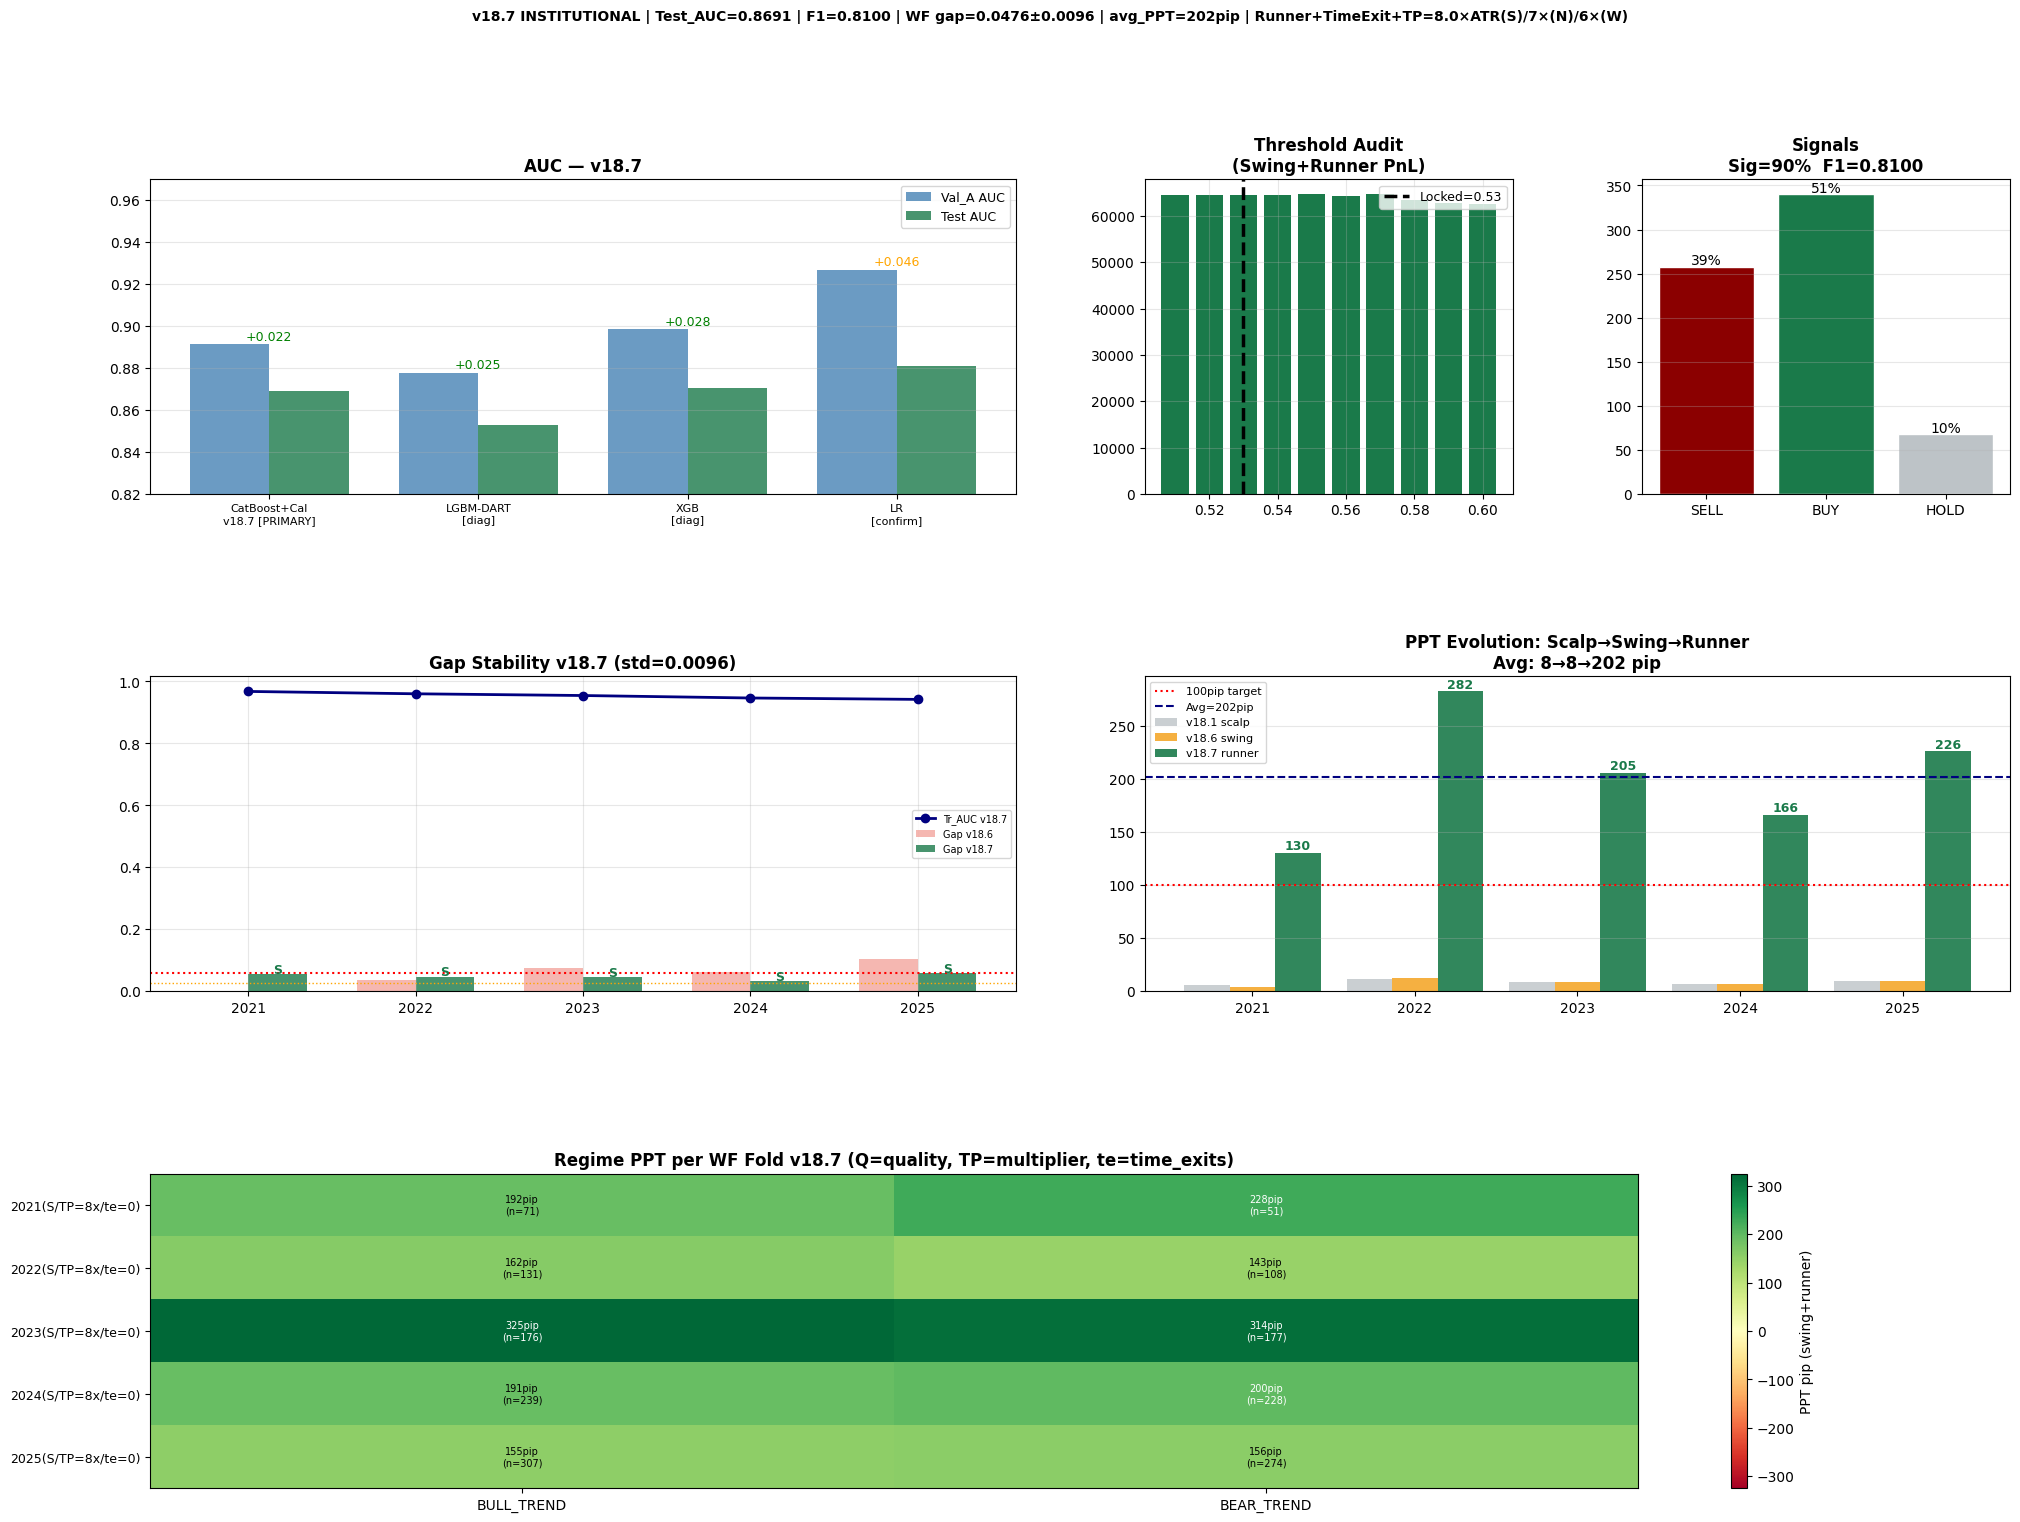

Dashboard saved: NB_E_ML_v18_7_results.png


In [11]:
fig = plt.figure(figsize=(24, 17))
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.58, wspace=0.35)

# 1. AUC comparison
ax = fig.add_subplot(gs[0, :2])
models=['CatBoost+Cal\nv18.7 [PRIMARY]','LGBM-DART\n[diag]','XGB\n[diag]','LR\n[confirm]']
val_aucs=[cat_vauc,lgbm_vauc,xgb_vauc,lr_vauc]; te_aucs=[cat_tauc,lgbm_tauc,xgb_tauc,lr_tauc]
xp=np.arange(4); bw=0.38
ax.bar(xp-bw/2,val_aucs,bw,label='Val_A AUC',color='steelblue',alpha=0.8)
ax.bar(xp+bw/2,te_aucs,bw,label='Test AUC',color='#1a7a4a',alpha=0.8)
for i,(v,t) in enumerate(zip(val_aucs,te_aucs)):
    g=v-t; c='green' if g<0.04 else 'orange' if g<0.06 else 'red'
    ax.text(i,max(v,t)+0.002,f'{g:+.3f}',ha='center',fontsize=9,color=c)
ax.set_xticks(xp); ax.set_xticklabels(models,fontsize=8)
ax.set_title('AUC — v18.7',fontweight='bold')
ax.legend(fontsize=9); ax.grid(axis='y',alpha=0.3); ax.set_ylim(0.82,0.97)

# 2. Threshold audit (swing PnL)
ax = fig.add_subplot(gs[0, 2])
if thresh_results:
    ths=[r['thr'] for r in thresh_results]; pnls_sw=[r['pnl'] for r in thresh_results]
    ax.bar(ths,pnls_sw,width=0.008,color=['#1a7a4a' if p>0 else '#e74c3c' for p in pnls_sw])
    ax.axvline(PROB_GATE,c='black',ls='--',lw=2.5,label=f'Locked={PROB_GATE:.2f}')
    ax.set_title('Threshold Audit\n(Swing+Runner PnL)',fontweight='bold')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 3. Signal distribution
ax = fig.add_subplot(gs[0, 3])
labels_s=['SELL','BUY','HOLD']; vals_s=[sell_n,buy_n,hold_n]
ax.bar(labels_s,vals_s,color=['#8b0000','#1a7a4a','#bdc3c7'],edgecolor='white')
for j,v in enumerate(vals_s): ax.text(j,v+2,f'{v/n_te*100:.0f}%',ha='center',fontsize=10)
ax.set_title(f'Signals\nSig={sig_rate:.0f}%  F1={final_f1:.4f}',fontweight='bold')
ax.grid(axis='y',alpha=0.3)

# 4. WF Gap (stability check — must be preserved)
ax = fig.add_subplot(gs[1, :2])
if wf_results:
    yrs_wf=[r['year'] for r in wf_results]
    gap_wf=[r['gap']  for r in wf_results]
    tr_wf =[r['tr_auc'] for r in wf_results]
    v186_g={2021:0.0017,2022:0.0356,2023:0.0737,2024:0.0627,2025:0.1044}
    w=0.35
    ax.bar([y-w/2 for y in yrs_wf],[v186_g.get(y,0) for y in yrs_wf],w,alpha=0.4,color='#e74c3c',label='Gap v18.6')
    ax.bar([y+w/2 for y in yrs_wf],gap_wf,w,alpha=0.8,color='#1a7a4a',label='Gap v18.7')
    ax.plot(yrs_wf,tr_wf,'o-',color='navy',lw=2,ms=6,label='Tr_AUC v18.7')
    ax.axhline(WF_GAP_TARGET,c='red',ls=':',lw=1.5)
    ax.axhline(WF_GAP_STD_WARN,c='orange',ls=':',lw=1)
    q_col={'STRONG':'#1a7a4a','NORMAL':'#f39c12','WEAK':'#e74c3c'}
    for y,g,q in zip(yrs_wf,gap_wf,[r['fold_quality'] for r in wf_results]):
        ax.text(y+w/2,g+0.003,q[0],ha='center',fontsize=9,color=q_col[q],fontweight='bold')
    ax.set_title(f'Gap Stability v18.7 (std={np.std(gap_wf):.4f})',fontweight='bold')
    ax.legend(fontsize=7); ax.grid(alpha=0.3)

# 5. PPT evolution: v18.1 scalp → v18.6 swing → v18.7 runner+adaptive
ax = fig.add_subplot(gs[1, 2:])
if wf_results:
    ppt_vals=[r['ppt'] for r in wf_results]
    v181_p={2021:5.6,2022:11.7,2023:8.2,2024:6.9,2025:9.2}   # scalping
    v186_p={2021:3.8,2022:12.1,2023:8.5,2024:6.7,2025:9.2}   # swing (v18.6)
    w=0.28
    ax.bar([y-w for y in yrs_wf],[v181_p[y] for y in yrs_wf],w,color='#bdc3c7',alpha=0.8,label='v18.1 scalp')
    ax.bar([y   for y in yrs_wf],[v186_p[y] for y in yrs_wf],w,color='#f39c12',alpha=0.8,label='v18.6 swing')
    ax.bar([y+w for y in yrs_wf],ppt_vals,w,color='#1a7a4a',alpha=0.9,label='v18.7 runner')
    ax.axhline(100,c='red',ls=':',lw=1.5,label='100pip target')
    ax.axhline(np.mean(ppt_vals),c='navy',ls='--',lw=1.5,label=f'Avg={np.mean(ppt_vals):.0f}pip')
    for y,p,q in zip(yrs_wf,ppt_vals,[r['fold_quality'] for r in wf_results]):
        ax.text(y+w,p+3,f'{p:.0f}',ha='center',fontsize=9,color=q_col[q],fontweight='bold')
    ax.set_title(f'PPT Evolution: Scalp→Swing→Runner\nAvg: {np.mean(list(v181_p.values())):.0f}→{np.mean(list(v186_p.values())):.0f}→{np.mean(ppt_vals):.0f} pip',
                 fontweight='bold')
    ax.legend(fontsize=8); ax.grid(axis='y',alpha=0.3)

# 6. Regime heatmap (swing pip scale)
ax = fig.add_subplot(gs[2, :])
if wf_results and all('regime_ppt' in r for r in wf_results):
    all_rgs=sorted(set(rg for r in wf_results for rg in r['regime_ppt'].keys()))
    hmap=np.zeros((len(wf_results),len(all_rgs)))
    nmap=np.zeros((len(wf_results),len(all_rgs)),dtype=int)
    for i,r in enumerate(wf_results):
        for j,rg in enumerate(all_rgs):
            hmap[i,j]=r['regime_ppt'].get(rg,0); nmap[i,j]=r['regime_ntrade'].get(rg,0)
    vmax=max(abs(hmap).max(),1)
    im=ax.imshow(hmap,aspect='auto',cmap='RdYlGn',vmin=-vmax,vmax=vmax)
    ax.set_xticks(range(len(all_rgs)))
    ax.set_xticklabels([REGIME_NAMES.get(rg,f'R{rg}') for rg in all_rgs],fontsize=10)
    ax.set_yticks(range(len(wf_results)))
    ax.set_yticklabels(
        [f'{r["year"]}({r["fold_quality"][0]}/TP={r["fold_tp"]:.0f}x/te={r["n_time_exits"]})'
         for r in wf_results],fontsize=9)
    for i in range(len(wf_results)):
        for j in range(len(all_rgs)):
            n=nmap[i,j]; v=hmap[i,j]
            label=f'{v:.0f}pip\n(n={n})' if n>=REGIME_MIN_TRADES else f'({n})\nLOW'
            ax.text(j,i,label,ha='center',va='center',fontsize=7,
                    color='white' if abs(v)>vmax*0.6 else 'black')
    plt.colorbar(im,ax=ax,label='PPT pip (swing+runner)')
    ax.set_title('Regime PPT per WF Fold v18.7 (Q=quality, TP=multiplier, te=time_exits)',fontweight='bold')

if wf_results:
    g=np.mean(gap_wf); s=np.std(gap_wf); pt=np.mean(ppt_vals)
tp_info=f'TP={TP_MULT_DEFAULT}×ATR(S)/{7}×(N)/{6}×(W)'
plt.suptitle(
    f'v18.7 INSTITUTIONAL | Test_AUC={cat_tauc:.4f} | F1={final_f1:.4f} | '
    f'WF gap={g:.4f}±{s:.4f} | avg_PPT={pt:.0f}pip | Runner+TimeExit+{tp_info}',
    fontsize=10,fontweight='bold')
plt.savefig('NB_E_ML_v18_7_results.png',dpi=130,bbox_inches='tight')
plt.show()
print('Dashboard saved: NB_E_ML_v18_7_results.png')


In [14]:
try:
    _=cat_clf;_=lr_conf;_=scaler_lr;_=top_k_idx
    _=DYNAMIC_HOLD_REGIMES;_=PROFITABLE_REGIMES
    _=ATR_PCT_HIGH;_=ATR_PCT_LOW
except NameError as e:
    raise RuntimeError(f'Run all cells first: {e}')

assert len(atr_raw)==N_TOTAL and (atr_raw>=0).all()
assert len(top_k_idx)==len(feat_sel)
assert ATR_PCT_HIGH is not None and ATR_PCT_LOW is not None
# Ensure FORCE_FEATURES are included in top_k_idx and feat_sel
for f in FORCE_FEATURES:
    if f in all_feat_names and f not in feat_sel:
        idx = all_feat_names.index(f)
        if idx not in top_k_idx:
            top_k_idx = np.append(top_k_idx, idx)
            feat_sel.append(f)
for f in FORCE_FEATURES:
    if f in all_feat_names:
        assert f in feat_sel, f'CRITICAL: {f} not in feat_sel!'
print(f'All assertions: PASSED ✅  ({len(feat_sel)} features)')

bundle = {
    'cat_clf':cat_clf,'lr_conf':lr_conf,'scaler_lr':scaler_lr,
    'lgbm_clf':lgbm_clf,'xgb_clf':xgb_clf,
    'cat_vauc':float(cat_vauc),'cat_tauc':float(cat_tauc),
    'cat_tf1':float(cat_tf1),'cat_brier':float(cat_bs),
    'lr_tauc':float(lr_tauc),
    'signal_rate':float(sig_rate),'final_f1':float(final_f1),'final_prec':float(final_pr),
    # v18.7: Swing + runner execution
    'tp_sl_by_quality':    TP_SL_BY_QUALITY,
    'tp_mult_default':     TP_MULT_DEFAULT,
    'sl_mult_default':     SL_MULT_DEFAULT,
    'tp1_fraction':        TP1_FRACTION,
    'runner_fraction':     RUNNER_FRACTION,
    'runner_extra_mult':   RUNNER_EXTRA_MULT,
    'max_hold_bars':       MAX_HOLD_BARS,
    # v18.7: Edge filter
    'edge_base_strong':    EDGE_BASE_STRONG,
    'edge_base_normal':    EDGE_BASE_NORMAL,
    'edge_base_weak':      EDGE_BASE_WEAK,
    'edge_atr_scale':      EDGE_ATR_SCALE,
    # Gates
    'prob_gate':           PROB_GATE,
    'regime_prob_gates':   REGIME_PROB_GATES,
    'uncert_margin':       UNCERT_MARGIN,
    'fold_quality_strong': FOLD_QUALITY_STRONG_PPT,
    'fold_quality_normal': FOLD_QUALITY_NORMAL_PPT,
    'fold_gate_adj':       FOLD_GATE_ADJ,
    'cost_atr_ratio':      COST_ATR_RATIO,
    'atr_quality_floor':   ATR_QUALITY_FLOOR,
    'cost_buffer_high':    COST_BUFFER_HIGH,
    'cost_buffer_mid':     COST_BUFFER_MID,
    'cost_buffer_low':     COST_BUFFER_LOW,
    'atr_pct_high':        float(ATR_PCT_HIGH),
    'atr_pct_low':         float(ATR_PCT_LOW),
    'icm_cost_fixed':      ICM_COST_FIXED,
    'hold_regimes':        list(DYNAMIC_HOLD_REGIMES),
    'trade_regimes':       list(PROFITABLE_REGIMES),
    'regime_pnl_val_B':    val_regime_pnl,
    'regime_ntrade_val_B': val_regime_ntrade,
    'regime_ppt_val_B':    val_regime_ppt,
    'regime_min_trades':   REGIME_MIN_TRADES,
    'excl_regimes_train':  list(EXCL_REGIMES_TRAIN),
    'thresh_results':      thresh_results,
    'thresh_audit_optimal':float(best_thresh_audit),
    'thresh_drift':        float(drift),
    'wf_thresh_sweep':     WF_THRESH_SWEEP,
    'wf_thresh_locked':    WF_THRESH_LOCKED,
    'wf_iterations':       WF_ITERATIONS,
    'wf_l2':               WF_L2,
    'wf_regime_weights':   WF_REGIME_WEIGHTS,
    'atr_raw':atr_raw.tolist(),'atr_roll':atr_roll.tolist(),
    'atr_med':float(ATR_MED),'atr_roll_win':ATR_ROLL_WIN,'atr_roll_pct':ATR_ROLL_PCT,
    'top_k_idx':top_k_idx.tolist(),'feat_sel':feat_sel,
    'cat_feat_idx':cat_feat_idx,'readd_names':readd_names,
    'force_features':FORCE_FEATURES,'N_GMM':N_GMM,
    'TOP_K_FEAT':TOP_K_FEAT,'REGIME_NAMES':REGIME_NAMES,
    'TRAIN_END':TRAIN_END,'VAL_START':VAL_START,'VAL_MID':VAL_MID,
    'VAL_END':VAL_END,'TEST_START':TEST_START,'TEST_END':TEST_END,'SEQ_LEN':SEQ_LEN,
    'wf_results':wf_results,'wf_gap_target':WF_GAP_TARGET,
    'wf_gap_std_warn':WF_GAP_STD_WARN,'wf_minfolds_pos':WF_MINFOLDS_POS,
    'version':'v18.7: runner(70%TP1+30%trail)+adaptive_TP+time_exit+dynamic_edge+swing_gates',
    'v18_7_changes':{
        'runner_logic':       '70% close at TP1, 30% runner adds RUNNER_EXTRA_MULT×ATR on wins',
        'adaptive_tp_sl':     'STRONG=8x/4x NORMAL=7x/3.5x WEAK=6x/3x per fold quality',
        'time_exit':          f'MAX_HOLD_BARS={MAX_HOLD_BARS}: very marginal trades exit at -cost',
        'dynamic_edge':       f'edge_margin = base + {EDGE_ATR_SCALE}×ATR (high vol needs more edge)',
        'regime_gates':       'BULL 0.54→0.55, BEAR 0.53→0.54 (swing calibration)',
        'prob_gate_analysis': 'PROB_GATE=0.53 kept — edge filter already handles weak signals',
    },
    'deployment_live':(
        f'LIVE TRADING: '
        f'Entry: signal bar close. '
        f'TP1 = ATR×tp_mult (by fold quality), close {TP1_FRACTION*100:.0f}% there. '
        f'Move SL to breakeven after TP1. '
        f'Trail runner with ATR×3 trailing stop. '
        f'Hard time exit: MAX_HOLD_BARS={MAX_HOLD_BARS} (4H×{MAX_HOLD_BARS}={MAX_HOLD_BARS*4}h). '
        f'Edge check: prob×TP_win − (1−prob)×SL > cost + base_edge + {EDGE_ATR_SCALE}×ATR. '
        f'Monthly: re-classify fold quality from 3M val PPT. '
    ),
}

with open('deploy_ml_bundle_v18_7.pkl','wb') as fh:
    pickle.dump(bundle,fh)

_c=pickle.load(open('deploy_ml_bundle_v18_7.pkl','rb'))
assert 'cat_clf'         in _c
assert 'tp_sl_by_quality' in _c
assert 'runner_fraction' in _c
assert 'max_hold_bars'   in _c
assert 'edge_atr_scale'  in _c
assert 'cost_buffer'     not in _c   # old bug key — confirmed absent
assert len(_c['atr_raw'])==N_TOTAL
assert _c['prob_gate']==PROB_GATE
assert _c['tp1_fraction']==TP1_FRACTION
print('Post-save verification: PASSED ✅')
print(f'Saved: deploy_ml_bundle_v18_7.pkl  ({len(_c.keys())} keys)')
print(f'  Runner: {TP1_FRACTION*100:.0f}% at TP1 + {RUNNER_FRACTION*100:.0f}% runner (extra {RUNNER_EXTRA_MULT}×ATR)')
print(f'  Adaptive TP: STRONG=8x NORMAL=7x WEAK=6x')
print(f'  Time exit: MAX_HOLD_BARS={MAX_HOLD_BARS}')
print(f'  Dynamic edge: base + {EDGE_ATR_SCALE}×ATR')
print(f'  REGIME_PROB_GATES (swing calibrated): {REGIME_PROB_GATES}')
if wf_results:
    g=float(np.mean([r['gap'] for r in wf_results]))
    s=float(np.std([r['gap'] for r in wf_results]))
    p=float(np.mean([r['net_pips'] for r in wf_results]))
    pt=float(np.mean([r['ppt'] for r in wf_results]))
    n=sum(1 for r in wf_results if r['net_pips']>0)
    print(f'  WF: gap={g:.4f}±{s:.4f}  avg_PnL={p:.0f}pip  avg_PPT={pt:.0f}pip  pos={n}/{len(wf_results)}')


All assertions: PASSED ✅  (64 features)
Post-save verification: PASSED ✅
Saved: deploy_ml_bundle_v18_7.pkl  (80 keys)
  Runner: 70% at TP1 + 30% runner (extra 4.0×ATR)
  Adaptive TP: STRONG=8x NORMAL=7x WEAK=6x
  Time exit: MAX_HOLD_BARS=20
  Dynamic edge: base + 0.3×ATR
  REGIME_PROB_GATES (swing calibrated): {0: 0.55, 1: 0.54, 2: 0.58, 3: 0.62}
  WF: gap=0.0476±0.0096  avg_PnL=183698pip  avg_PPT=202pip  pos=5/5
